# Groups of subjects: a hierarchy of templates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/13_group_hierarchy.ipynb)

HTFA ties every subject's factors to one global template. With `groups`, `HTFA.fit` fits one template per group of subjects under the global template instead: each subject's prior is centred on its group's template, each group's prior on the global template, and factor `k` is the same factor in every template. Groups can be nested further (for example sites, then diagnoses within each site). `htfa.group_permutation_test` then asks, factor by factor, whether the groups differ in where a factor is (its center), how large it is (its width) or how it is connected to the other factors, by shuffling the group labels and refitting.

**Data used in each section.**

- Sections 1 to 3: synthetic data from `htfa.make_group_data`, with known group differences (section 1), with none (section 2, a control for false positives) and with two nested levels (section 3).
- Sections 4 to 7: ten children (3 to 4 years old) and ten adults of nilearn's `development_fmri` dataset (Pixar "Partly Cloudy" viewing, 168 volumes, TR = 2 s), with a template for each age group under a template of people in general.

The first run downloads the twenty runs of the dataset (about 25 MB each) and, by default, the saved fit and permutation null of section 4 (see there); later runs reuse the downloaded files.

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q htfa

In [2]:
import json
import os
import time
import warnings

import numpy as np
from sklearn.exceptions import ConvergenceWarning

import htfa
from htfa.groups import GroupTest, group_tree
from htfa.synthetic import match_factors

plt = htfa.require("matplotlib.pyplot")
warnings.filterwarnings("ignore", category=ConvergenceWarning)
T_START = time.perf_counter()

## 1. Synthetic groups with known differences

`htfa.make_group_data` draws a global template, moves it per group (`center_shift`, `width_scale`) and draws each group's subjects around their group's template, as `make_htfa_data` does around the global one. Here two groups of 5 subjects share 5 factors on a 16 x 16 grid; in group 1, factor 0 moves 3 grid units along the first axis (toward the middle of the grid) and factor 1 is twice as wide. Subjects scatter around their group template by 0.5 grid units (`center_jitter`).

In [3]:
K = 5
SIZES = (5, 5)


def group_data(shift, scale, seed):
    # the global centers do not depend on the shifts: move factor 0 toward the
    # middle of the grid so that it stays inside
    g = htfa.make_group_data(SIZES, (16, 16), 2, K=K, random_state=seed)[3]
    toward = -np.sign(g["global_centers"][0, 0] - 7.5)
    center_shift = np.zeros((2, K, 2))
    center_shift[1, 0, 0] = toward * shift
    width_scale = np.ones((2, K))
    width_scale[1, 1] = scale
    return htfa.make_group_data(
        SIZES,
        grid_shape=(16, 16),
        n_samples=40,
        K=K,
        center_shift=center_shift,
        width_scale=width_scale,
        center_jitter=0.5,
        random_state=seed,
    )


Xs, Rs, groups, truth = group_data(shift=3.0, scale=2.0, seed=0)
print("subjects:", len(Xs), " groups:", groups)
print(
    "true group 1 - group 0, factor 0 center:",
    truth["group_centers"][1, 0] - truth["group_centers"][0, 0],
)
print(
    "true width ratio, factor 1:",
    truth["group_widths"][1, 1] / truth["group_widths"][0, 1],
)

subjects: 10  groups: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
true group 1 - group 0, factor 0 center: [-3.  0.]
true width ratio, factor 1: 2.0


Groups need `template_update='fixed'` or `'empirical'` (BrainIAK's update, the default, takes its prior from its own previous estimate rather than from a parent template, and raises an error with groups). The fit returns the global template (`global_centers_`), one template per group (`group_centers_`, `group_widths_`, keyed by `group_keys_`) and their posterior covariances (`group_centers_cov_`).

In [4]:
t0 = time.perf_counter()
model = htfa.HTFA(K=K, template_update="fixed", standardize=False, random_state=0)
model.fit(Xs, Rs, groups=groups)
print(
    f"fit: {time.perf_counter() - t0:.1f} s, {model.n_iter_} global iterations "
    f"({model.converged_reason_})"
)
print("group keys:", model.group_keys_)
print(
    "group_centers_:",
    model.group_centers_.shape,
    " group_centers_cov_:",
    model.group_centers_cov_.shape,
)

perm = match_factors(truth["global_centers"], model.global_centers_)  # truth order
est = model.group_centers_[:, perm]
sd = np.sqrt(model.group_centers_cov_[:, perm, 0, 0])
print("\nfactor | estimated group 1 - group 0 (axis 0, axis 1) | true | posterior SD")
for k in range(K):
    d = est[1, k] - est[0, k]
    t = truth["group_centers"][1, k] - truth["group_centers"][0, k]
    print(
        f"  {k}    | {d[0]:6.2f} {d[1]:6.2f}                          "
        f"| {t[0]:4.1f} {t[1]:4.1f} | {sd[0, k]:.2f}"
    )
ratio = model.group_widths_[1, perm] / model.group_widths_[0, perm]
print("\nwidth ratio group 1 / group 0:", np.round(ratio, 2))

fit: 0.6 s, 2 global iterations (threshold)
group keys: [0, 1]
group_centers_: (2, 5, 2)  group_centers_cov_: (2, 5, 2, 2)

factor | estimated group 1 - group 0 (axis 0, axis 1) | true | posterior SD
  0    |  -3.03  -0.11                          | -3.0  0.0 | 1.16
  1    |  -0.14   0.13                          |  0.0  0.0 | 1.16
  2    |  -0.10  -0.35                          |  0.0  0.0 | 1.16
  3    |  -0.03  -0.23                          |  0.0  0.0 | 1.16
  4    |  -0.02   0.22                          |  0.0  0.0 | 1.16

width ratio group 1 / group 0: [1.05 1.78 0.99 0.99 0.99]


Factor 0's estimated move is close to the true 3 grid units and the other factors barely move. Each group template is pulled toward the global template as if by one extra subject placed there: for two groups of 5 the estimated difference is 5/6 of the difference between the groups' subject means (which here is itself not exactly 3, since only five subjects per group scatter around each template). The width ratio of factor 1 is shrunk the same way.

The figure shows the mean image of subject 0 with the true group templates (open markers) and the estimated ones (filled), using `HTFAResults.plot_nodes(group=...)`, which draws a group template in black and its subjects' centers in color.

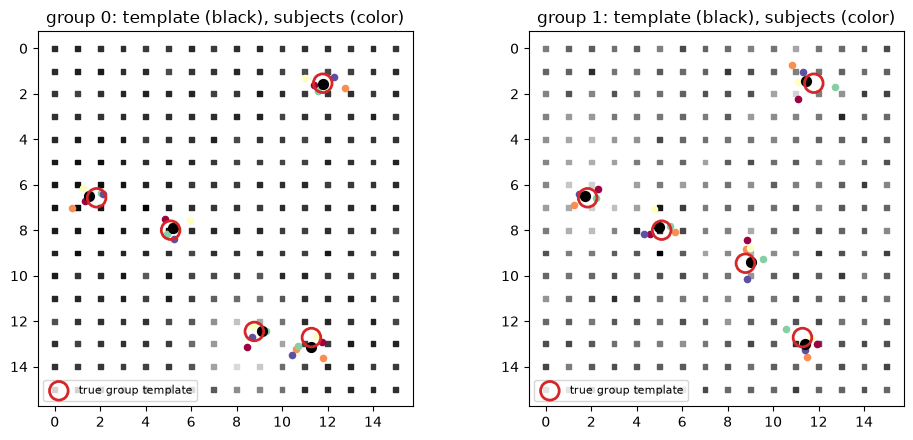

In [5]:
res = htfa.HTFAResults(model, htfa.load(Xs, coords=Rs))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, g in zip(axes, model.group_keys_, strict=True):
    res.plot_nodes(group=g, ax=ax, snap=False)
    tc = truth["group_centers"][g]
    ax.scatter(
        tc[:, 1],
        tc[:, 0],
        s=180,
        facecolors="none",
        edgecolors="tab:red",
        linewidths=2,
        zorder=5,
        label="true group template",
    )
    ax.set_title(f"group {g}: template (black), subjects (color)")
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### The permutation test

`htfa.group_permutation_test(model, X, coords, n_permutations, random_state)` refits the model with the group labels shuffled among the subjects (`n_permutations` times; the unpenalized first-stage fits are reused, since they do not depend on the labels) and compares three statistics per factor with their permutation distributions:

- `center`: how far the group templates' centers are from their (subject-weighted) mean, in coordinate units; for two groups it is proportional to the distance between them;
- `width`: the same for the log widths;
- `connectivity`: the same for the factor's row of the groups' mean (Fisher z) static connectivity.

`test.pvalues(stat)` gives `(1 + number of permutations at least as large) / (1 + n_permutations)` per factor; `test.pvalues(stat, fwe=True)` compares each factor with the largest statistic over all factors of each permutation, which provides a max-statistic correction across the K factors under the permutation test's exchangeability assumptions. With 39 permutations the smallest possible p-value is 1/40 = 0.025.

In [6]:
t0 = time.perf_counter()
test = htfa.group_permutation_test(model, Xs, Rs, n_permutations=39, random_state=0)
print(f"39 refits: {time.perf_counter() - t0:.1f} s")
for stat in ("center", "width", "connectivity"):
    print(f"{stat:>12} p (truth order):      ", np.round(test.pvalues(stat)[perm], 3))
    print(
        f"{stat:>12} p, family-wise:       ",
        np.round(test.pvalues(stat, fwe=True)[perm], 3),
    )

39 refits: 4.0 s
      center p (truth order):       [0.025 0.825 0.475 0.85  0.5  ]
      center p, family-wise:        [0.025 1.    0.975 1.    1.   ]
       width p (truth order):       [0.075 0.025 0.575 0.825 0.35 ]
       width p, family-wise:        [1.    0.025 1.    1.    1.   ]
connectivity p (truth order):       [0.975 0.475 0.875 0.85  0.65 ]
connectivity p, family-wise:        [1.    0.925 1.    1.    0.975]


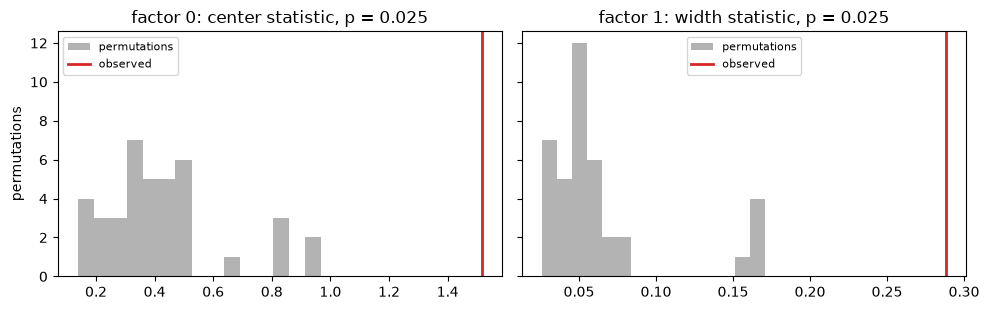

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, stat, k in zip(axes, ("center", "width"), (0, 1), strict=True):
    f = perm[k]  # model index of true factor k
    ax.hist(
        getattr(test, f"{stat}_null")[:, f], bins=15, color="0.7", label="permutations"
    )
    ax.axvline(getattr(test, stat)[f], color="tab:red", lw=2, label="observed")
    ax.set_title(f"factor {k}: {stat} statistic, p = {test.pvalues(stat)[f]:.3f}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("permutations")
plt.tight_layout()
plt.show()

## 2. A control: no true difference

The same generator with no shift and no width change: any difference between the group templates is noise. The p-values should then be spread over (0, 1], and below 0.05 for about 5% of the factors. One dataset says little about that rate; `docs/validation.rst` reports it over 200 datasets (`scripts/validation_groups.py fpr`).

In [8]:
Xs0, Rs0, groups0, truth0 = group_data(shift=0.0, scale=1.0, seed=1)
model0 = htfa.HTFA(K=K, template_update="fixed", standardize=False, random_state=0)
model0.fit(Xs0, Rs0, groups=groups0)
test0 = htfa.group_permutation_test(model0, Xs0, Rs0, n_permutations=39, random_state=0)
for stat in ("center", "width", "connectivity"):
    print(f"{stat:>12} p: ", np.round(test0.pvalues(stat), 3))

      center p:  [0.15  0.25  0.025 0.375 0.875]
       width p:  [0.9   0.7   0.975 0.375 0.675]
connectivity p:  [0.65  0.3   0.15  0.375 0.325]


## 3. Deeper nesting

`groups` can also be a list of label sequences, one per level, top level first. Here two sites each have controls and patients, and the patients of both sites have factor 0 moved. Labels must be nested: a label belongs to one label of the level above, so the patients of site A and of site B get different labels (a label shared by two sites would describe a crossed design, which raises an error, as does a subject in two groups when `subject_ids` are given). The templates form a tree: global, then the sites, then the four site-by-diagnosis groups.

In [9]:
center_shift = np.zeros((4, K, 2))
g = htfa.make_group_data((3, 3, 3, 3), (16, 16), 2, K=K, random_state=4)[3]
center_shift[[1, 3], 0, 0] = -np.sign(g["global_centers"][0, 0] - 7.5) * 3.0
Xn, Rn, _, truth_n = htfa.make_group_data(
    (3, 3, 3, 3),
    grid_shape=(16, 16),
    n_samples=40,
    K=K,
    center_shift=center_shift,
    center_jitter=0.5,
    random_state=4,
)
site = ["A"] * 6 + ["B"] * 6
diagnosis = (
    ["A-control"] * 3 + ["A-patient"] * 3 + ["B-control"] * 3 + ["B-patient"] * 3
)
nested = htfa.HTFA(K=K, template_update="fixed", standardize=False, random_state=0)
nested.fit(Xn, Rn, groups=[site, diagnosis])
print("group keys:", nested.group_keys_)
pn = match_factors(truth_n["global_centers"], nested.global_centers_)
print("factor 0, first coordinate, per template:")
print(f"  global: {nested.global_centers_[pn[0], 0]:.2f}")
for key, c in zip(nested.group_keys_, nested.group_centers_[:, pn[0], 0], strict=True):
    print(f"  {key}: {c:.2f}")
try:
    htfa.HTFA(K=K, template_update="fixed").fit(
        Xn,
        Rn,
        groups=[
            site,
            ["control"] * 3 + ["patient"] * 3 + ["control"] * 3 + ["patient"] * 3,
        ],
    )
except ValueError as err:
    print("\ncrossed labels:", err)

group keys: ['A', 'B', ('A', 'A-control'), ('A', 'A-patient'), ('B', 'B-control'), ('B', 'B-patient')]
factor 0, first coordinate, per template:
  global: 7.30
  A: 7.17
  B: 7.43
  ('A', 'A-control'): 6.00
  ('A', 'A-patient'): 8.20
  ('B', 'B-control'): 6.35
  ('B', 'B-patient'): 8.64

crossed labels: groups must be nested: label 'control' of level 1 appears under ["'A'", "'B'"] of level 0; give groups under different parents distinct labels (crossed designs are not supported)


`level` selects the level the permutation test compares. At `level=1` the diagnosis labels are shuffled among the subjects within each site, so site differences cannot create a diagnosis effect; at `level=0` whole site-by-diagnosis groups are moved between sites.

In [10]:
test_n = htfa.group_permutation_test(
    nested, Xn, Rn, n_permutations=19, level=1, random_state=0
)
print("compared groups:", test_n.groups)
print("center p (truth order):", np.round(test_n.pvalues("center")[pn], 3))

compared groups: [('A', 'A-control'), ('A', 'A-patient'), ('B', 'B-control'), ('B', 'B-patient')]
center p (truth order): [0.05 0.7  0.5  0.05 0.85]


## 4. Children and adults

Ten children (sub-pixar001 to sub-pixar010, 3.5 to 4.9 years old) and ten adults (sub-pixar123 to sub-pixar132) of `development_fmri`, preprocessed by `htfa.datasets.fetch_development_fmri` (MNI152 brain mask, voxels outside the subject's brain dropped, linear detrend and confound regression). nilearn picks children and adults in proportion when both are requested, so the children come from a request for 13 subjects of both groups (its first ten children) and the adults from a request for 10 adults.

The model has K = 30 factors, `template_update='fixed'` and the subsampling of `docs/performance.rst` (`max_voxels=3000`); `groups` gives each subject's age group, and `subject_ids` lets the fit check that each participant occurs only once. The global template is the "people in general" level above the two age-group templates.

By default (`REFIT = False`) the next cell downloads the saved fit with `htfa.datasets.fetch_tutorial_fit` from the `tutorial-data-v1` data release of the htfa repository, checks its SHA-256 and loads it with `np.load(..., allow_pickle=False)`; the printed lines describe the fitting settings. `REFIT = True` fits from scratch with one parallel job per CPU.

In [11]:
# Fit from scratch (True), or download the saved fit made with these settings
# (False, the default).
REFIT = False
# Optional cache directory; SHA-256 checks apply to cached files.
ASSET_CACHE = os.environ.get("HTFA_TUTORIAL_FITS")
NAME = "development_fmri_10children_10adults_K30"

settings = dict(
    K=30,
    template_update="fixed",
    max_global_iter=10,
    max_voxels=3000,
    init="ncorr",
    random_state=0,
)
both = htfa.datasets.fetch_development_fmri(n_subjects=13, adults_only=False)
kids = [i for i, a in enumerate(both.phenotypic["Child_Adult"]) if a == "child"][:10]
adults = htfa.datasets.fetch_development_fmri(n_subjects=10)
Xs = [both.data[i] for i in kids] + list(adults.data)
Rs = [both.coords[i] for i in kids] + list(adults.coords)
ids = [both.subject_ids[i] for i in kids] + list(adults.subject_ids)
labels = ["child"] * len(kids) + ["adult"] * len(adults.data)
ages = [float(both.phenotypic["Age"][i]) for i in kids] + list(adults.phenotypic["Age"])
print(
    "children:",
    ids[:10],
    "ages",
    np.round(min(ages[:10]), 1),
    "to",
    np.round(max(ages[:10]), 1),
)
print("adults:", ids[10:], "ages", min(ages[10:]), "to", max(ages[10:]))

if REFIT:
    t0 = time.perf_counter()
    model = htfa.HTFA(**settings, n_jobs=os.cpu_count()).fit(
        Xs, Rs, groups=labels, subject_ids=ids
    )
    fit_seconds = time.perf_counter() - t0
else:
    fit = htfa.datasets.fetch_tutorial_fit(NAME, cache_dir=ASSET_CACHE)
    saved = json.loads(str(fit["settings"]))
    assert saved == settings, saved
    assert list(fit["subject_ids"]) == ids and list(fit["labels"]) == labels
    print(f"saved fit: htfa.datasets.fetch_tutorial_fit({NAME!r}), SHA-256 checked")
    print("settings:", fit["settings"])
    model = htfa.HTFA(**settings)  # filled with the saved estimates
    model.centers_ = list(fit["centers"])
    model.widths_ = list(fit["widths"])
    model.weights_ = list(fit["weights"])
    model.free_fits_ = list(zip(fit["free_centers"], fit["free_widths"], strict=True))
    model.global_centers_ = fit["global_centers"]
    model.global_widths_ = fit["global_widths"]
    model.global_centers_cov_ = fit["global_centers_cov"]
    model.group_tree_ = group_tree(labels, len(labels), ids)
    model.group_keys_ = [str(k) for k in fit["group_keys"]]
    model.group_centers_ = fit["group_centers"]
    model.group_widths_ = fit["group_widths"]
    model.group_centers_cov_ = fit["group_centers_cov"]
    model.group_widths_var_ = fit["group_widths_var"]
    model.n_iter_ = int(fit["n_iter"])
    model.converged_reason_ = str(fit["converged_reason"])
    fit_seconds = float(fit["fit_seconds"])
res = htfa.HTFAResults(model, htfa.load(Xs, coords=Rs))
print(
    f"fit time: {fit_seconds:.0f} s; {model.n_iter_} global iterations "
    f"({model.converged_reason_})"
)
print(
    "groups:",
    model.group_keys_,
    " voxels per subject:",
    [s.data.shape[0] for s in res.subjects],
)

children: ['sub-pixar001', 'sub-pixar002', 'sub-pixar003', 'sub-pixar004', 'sub-pixar005', 'sub-pixar006', 'sub-pixar007', 'sub-pixar008', 'sub-pixar009', 'sub-pixar010'] ages 3.5 to 4.9
adults: ['sub-pixar123', 'sub-pixar124', 'sub-pixar125', 'sub-pixar126', 'sub-pixar127', 'sub-pixar128', 'sub-pixar129', 'sub-pixar130', 'sub-pixar131', 'sub-pixar132'] ages 19.0 to 39.0
saved fit: htfa.datasets.fetch_tutorial_fit('development_fmri_10children_10adults_K30'), SHA-256 checked
settings: {"K": 30, "template_update": "fixed", "max_global_iter": 10, "max_voxels": 3000, "init": "ncorr", "random_state": 0}
fitted with htfa 0.1.0 at commit 4c358d4a62f44e28d440709e53d6e97144504c93 on arm64 Darwin 12 CPUs
fit time: 86 s; 10 global iterations (plateau)
groups: ['child', 'adult']  voxels per subject: [26990, 26755, 27337, 27790, 28765, 28626, 28945, 28214, 29270, 27988, 25079, 23726, 26739, 27257, 27038, 27918, 27358, 27264, 27525, 27986]


## 5. Three templates

`res.group_centers` and `res.group_widths` hold the group templates by label; `res.global_centers` is the template of people in general. Below, the in-brain node positions (`display_nodes`, as the plots draw them) of the three templates on one glass brain, then each age group's template with its subjects' factors (`plot_nodes(group=...)`).

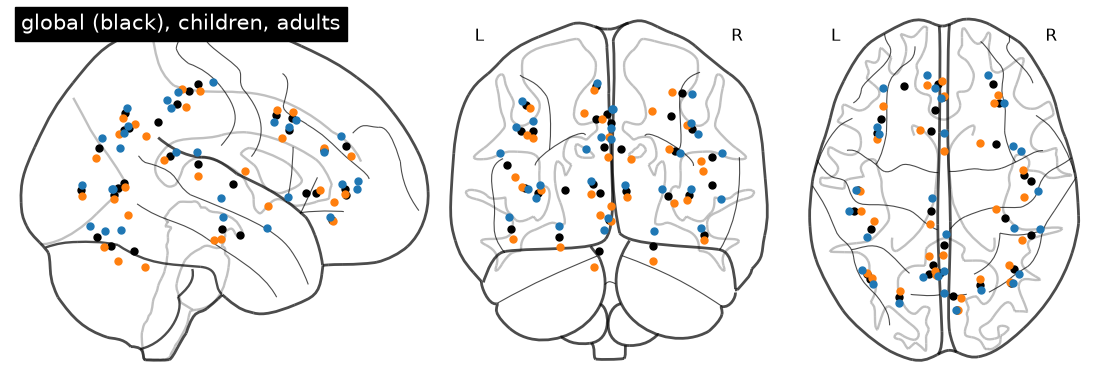

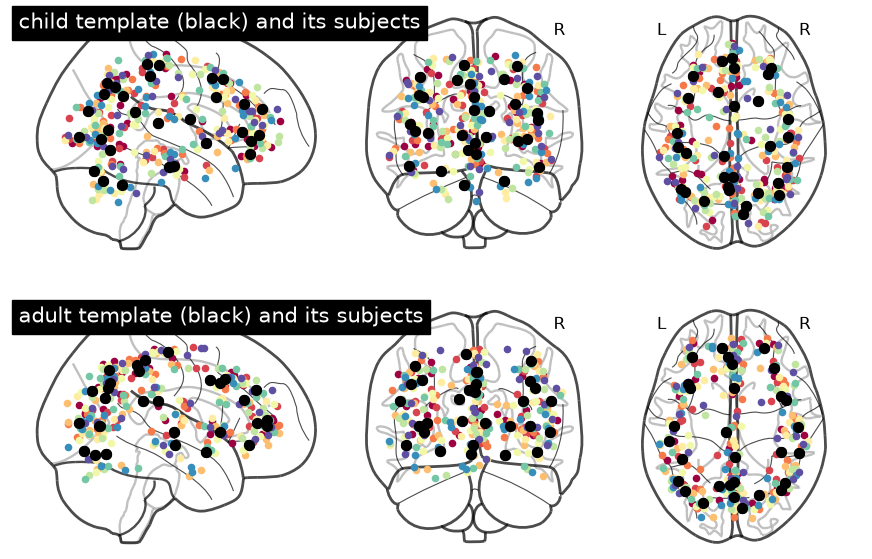

In [12]:
plotting = htfa.require("nilearn.plotting")
colors = {"child": "tab:orange", "adult": "tab:blue"}
fig = plt.figure(figsize=(11, 3.6))
disp = plotting.plot_connectome(
    np.zeros((30, 30)),
    res.display_nodes()[0],
    node_color="black",
    node_size=25,
    figure=fig,
    title="global (black), children, adults",
    colorbar=False,
)
for g, col in colors.items():
    disp.add_markers(res.display_nodes(group=g)[0], marker_color=col, marker_size=25)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, g in zip(axes, ("child", "adult"), strict=True):
    res.plot_nodes(group=g, ax=ax, title=f"{g} template (black) and its subjects")
plt.show()

In [13]:
child, adult = res.group_centers["child"], res.group_centers["adult"]
dist = np.linalg.norm(child - adult, axis=1)
sd = {
    g: np.sqrt(np.trace(model.group_centers_cov_[i], axis1=1, axis2=2) / 3)
    for i, g in enumerate(model.group_keys_)
}
ratio = res.group_widths["child"] / res.group_widths["adult"]
print(
    "child-adult template distance (mm): median "
    f"{np.median(dist):.1f}, max {dist.max():.1f}"
)
print(
    "posterior SD per coordinate (mm), median over factors:",
    {g: round(float(np.median(v)), 1) for g, v in sd.items()},
)
print(
    "width ratio child / adult: median "
    f"{np.median(ratio):.2f}, range {ratio.min():.2f} to {ratio.max():.2f}"
)

child-adult template distance (mm): median 16.3, max 49.2
posterior SD per coordinate (mm), median over factors: {'child': 3.5, 'adult': 3.5}
width ratio child / adult: median 1.24, range 0.66 to 2.06


The posterior SD comes from the fit's subject-level prior covariance and the tree (each group template is informed by its ten subjects and by the global template); it describes the uncertainty of a template given the subjects' estimates under that prior, not a sampling error over people. Whether the child and adult templates differ more than chance is what the permutation test answers.

## 6. Do children and adults differ?

`res.group_permutation_test(n_permutations=100, random_state=0)` refits the model 100 times with the 20 age labels shuffled. This requires many refits, so by default (`RECOMPUTE_NULL = False (unless REFIT is True)`) the saved result is downloaded instead; it corresponds to the saved fit above and records that fit's SHA-256.

In [14]:
RECOMPUTE_NULL = REFIT
if REFIT and not RECOMPUTE_NULL:
    raise ValueError("A new fit requires its own recomputed permutation test")
NULL_NAME = "development_fmri_children_adults_null_100"
if RECOMPUTE_NULL:
    test = res.group_permutation_test(n_permutations=100, random_state=0, verbose=True)
else:
    saved = htfa.datasets.fetch_tutorial_fit(NULL_NAME, cache_dir=ASSET_CACHE)
    if not REFIT:
        assert str(saved["fit_sha256"]) == htfa.datasets.TUTORIAL_FITS[NAME][1]
    test = GroupTest.from_arrays(saved)
    print(
        f"saved null: htfa.datasets.fetch_tutorial_fit({NULL_NAME!r}), SHA-256 checked"
    )
print(f"{len(test.center_null)} permutations")
if RECOMPUTE_NULL:
    print(f"permutation time: {test.seconds / 60:.0f} min")
for stat in ("center", "width", "connectivity"):
    p, q = test.pvalues(stat), test.pvalues(stat, fwe=True)
    print(
        f"{stat:>12}: {(p <= 0.05).sum():2d} of 30 factors with p <= 0.05 "
        f"(about 1.5 expected by chance), {(q <= 0.05).sum():2d} family-wise; "
        f"smallest p {p.min():.3f}"
    )

saved null: htfa.datasets.fetch_tutorial_fit('development_fmri_children_adults_null_100'), SHA-256 checked; htfa commit 4c358d4a62f44e28d440709e53d6e97144504c93
100 permutations, 113 min
      center:  2 of 30 factors with p <= 0.05 (about 1.5 expected by chance),  0 family-wise; smallest p 0.030
       width:  1 of 30 factors with p <= 0.05 (about 1.5 expected by chance),  0 family-wise; smallest p 0.050
connectivity:  2 of 30 factors with p <= 0.05 (about 1.5 expected by chance),  0 family-wise; smallest p 0.020


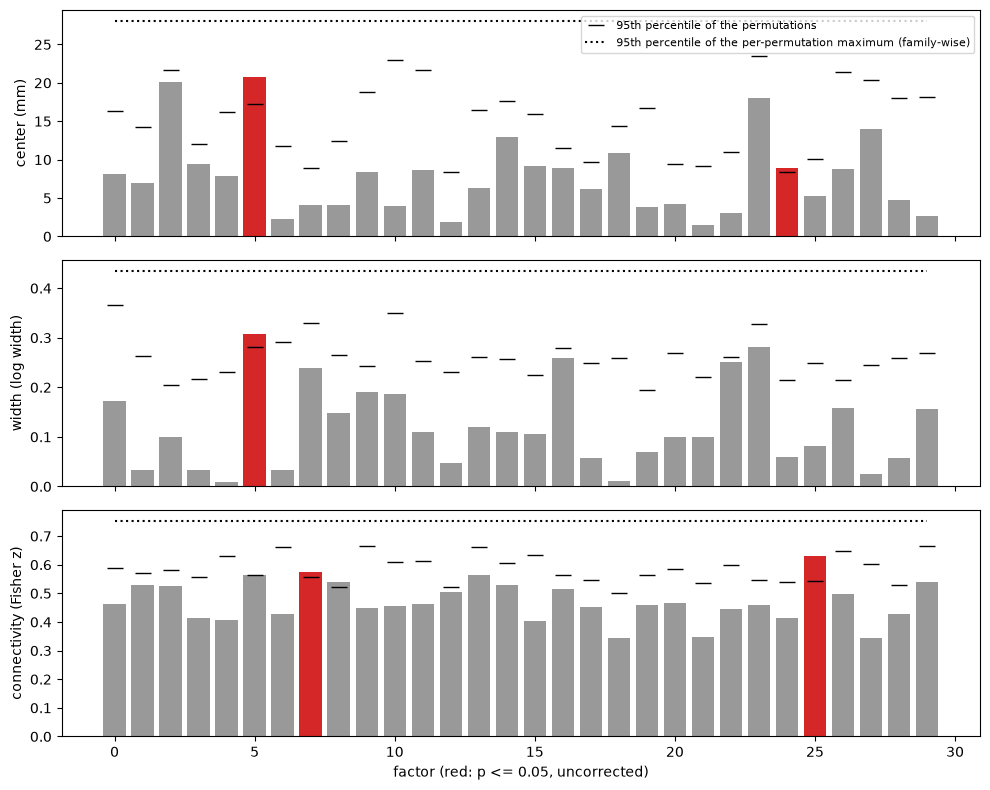

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, stat, unit in zip(
    axes,
    ("center", "width", "connectivity"),
    ("mm", "log width", "Fisher z"),
    strict=True,
):
    obs, null = getattr(test, stat), getattr(test, f"{stat}_null")
    order = np.arange(30)
    ax.bar(order, obs, color=np.where(test.pvalues(stat) <= 0.05, "tab:red", "0.6"))
    ax.plot(
        order,
        np.percentile(null, 95, axis=0),
        "k_",
        ms=12,
        label="95th percentile of the permutations",
    )
    ax.plot(
        order,
        np.full(30, np.percentile(null.max(axis=1), 95)),
        "k:",
        label="95th percentile of the per-permutation maximum (family-wise)",
    )
    ax.set_ylabel(f"{stat} ({unit})")
axes[0].legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("factor (red: p <= 0.05, uncorrected)")
plt.tight_layout()
plt.show()

The factors whose center differs at the family-wise level, drawn as segments from the child template (orange) to the adult template (blue):

In [16]:
sig = np.flatnonzero(test.pvalues("center", fwe=True) <= 0.05)
print("factors:", sig.tolist())
for k in sig:
    print(
        f"  factor {k}: child {np.round(child[k], 1)}, adult {np.round(adult[k], 1)}, "
        f"{dist[k]:.1f} mm apart, p = {test.pvalues('center')[k]:.3f}, "
        f"family-wise {test.pvalues('center', fwe=True)[k]:.3f}"
    )
if len(sig):
    pairs = np.vstack([child[sig], adult[sig]])
    n = len(sig)
    adj = np.zeros((2 * n, 2 * n))
    adj[np.arange(n), n + np.arange(n)] = adj[n + np.arange(n), np.arange(n)] = 1
    fig = plt.figure(figsize=(11, 3.6))
    plotting.plot_connectome(
        adj,
        pairs,
        node_color=["tab:orange"] * n + ["tab:blue"] * n,
        node_size=30,
        edge_kwargs={"color": "k"},
        figure=fig,
        title="center differences (family-wise p <= 0.05)",
    )
    plt.show()

factors: []


## 7. Connectivity by group

The connectivity statistic compares each factor's row of the groups' mean static connectivity. Below, the inter-subject functional correlation (ISFC) of each group, with the factors in the same order; `res.plot_network(group=...)` and `res.animate_network(group=...)` draw it on a 3D brain (they need the `brain3d` extra).

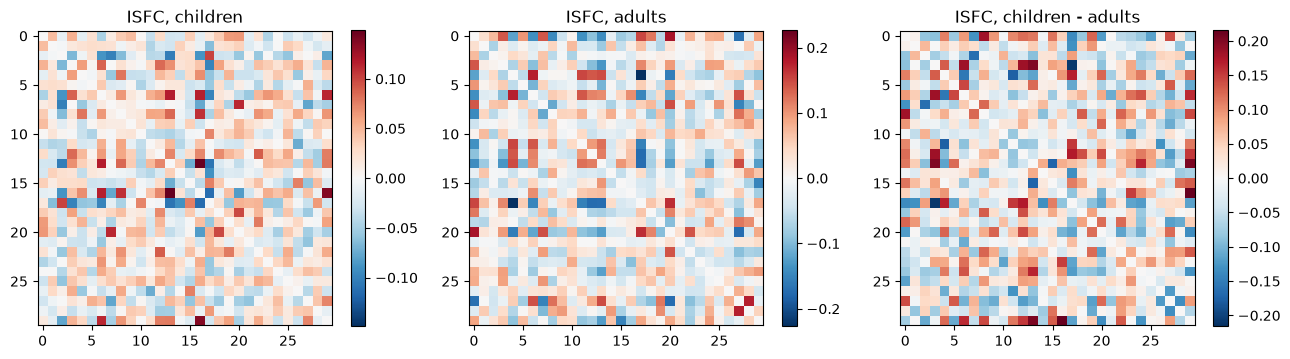

connectivity p <= 0.05 for factors [7, 25] ; family-wise: []
notebook run time: 17 s


In [17]:
isfc = {
    g: htfa.isfc([res.weights[s] for s in res.group_subjects(g)])
    for g in ("child", "adult")
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (title, m) in zip(
    axes,
    [
        ("children", isfc["child"]),
        ("adults", isfc["adult"]),
        ("children - adults", isfc["child"] - isfc["adult"]),
    ],
    strict=True,
):
    m = m.copy()
    np.fill_diagonal(m, 0)
    lim = np.abs(m).max()
    im = ax.imshow(m, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"ISFC, {title}")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
p = test.pvalues("connectivity")
print(
    "connectivity p <= 0.05 for factors",
    np.flatnonzero(p <= 0.05).tolist(),
    "; family-wise:",
    np.flatnonzero(test.pvalues("connectivity", fwe=True) <= 0.05).tolist(),
)
print(f"notebook run time: {time.perf_counter() - T_START:.0f} s")

**Saved-run result.** With these 20 participants, 100 permutations, and 30
factors, no center, width, or connectivity differences survive the max-statistic
correction across factors. Two centers, one width, and two connectivity rows have
uncorrected p <= 0.05; these exploratory findings do not establish a reliable
group difference after correction. The coarse p-value resolution is 1/101.


**Caveats.** Ten subjects per group is a small sample. Children of this age move more and have smaller heads, and the data are in a common (MNI) space after registration, so template differences can reflect registration and motion as well as functional organization; the test assesses group differences, not their cause. The p-values are per factor; use the family-wise ones when looking for any difference among the 30 factors.